# Razer Social Media Analytics
## NMC5342 Group 09 — Complete report and reproducible analysis

**Wang Xinyang · Li Yunrui · Wu Xia**

This notebook contains the complete text, nine figures, references, word-count note,
and contribution statement from the final Word report. The original report wording is
retained. Additional cells labelled **Reproducible analysis** provide calculations and
code provenance; they are not part of the Word report's stated word count.

All nine original figures and the executed analysis outputs are embedded, so the report
can be read directly on GitHub or after downloading this `.ipynb` alone.

**To rerun:** use the local NMC5342 research folder, normally `F:/NMC5342`, or set the
environment variable `NMC5342_ROOT` to its location. Install the lightweight packages
with `python -m pip install pandas matplotlib openpyxl ipykernel`, open the notebook in
Jupyter or VS Code, select that Python environment, and choose **Restart Kernel and Run All**.
The setup cell checks the exact source-file hashes used by this report.

The default run recomputes aggregate results from the local saved assignments and reruns
the original Brand24 Stage Final v2 cleaner. Raw comments and per-document assignment
files are read locally; they are not embedded in this notebook. The code writes temporary
results to `_razer_reproduction` beside the notebook. Optional model refitting and
Instagram language screening are disabled by default and call the original scripts
under the local project's `script` directory. The saved model settings are displayed below.

Repository: [nmc5342-razer-social-listening](https://github.com/Costawang/nmc5342-razer-social-listening)

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import importlib.util
import json
import os
import subprocess
import sys

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT = Path(os.environ.get("NMC5342_ROOT", "F:/NMC5342"))
if not PROJECT.is_dir():
    raise FileNotFoundError("Set NMC5342_ROOT to your local research folder; the report remains readable without running code.")
CODE = PROJECT / "script"
IG_RUN = PROJECT / "outputs/bertopic_instagram_bge_v31/20261103_003538_350286"
BRAND24_RUN = PROJECT / "outputs/bertopic_bge_v2/20261028_022514"
RUN = Path.cwd() / "_razer_reproduction"
RUN.mkdir(parents=True, exist_ok=True)
SOURCE_HASHES = {
    "outputs/bertopic_instagram_bge_v31/20261103_003538_350286/document_topics.csv": "1dee6bccd167b8e842f354c5080fb776d27081115e1d8d4113771d64eea4689b",
    "outputs/bertopic_instagram_bge_v31/20261103_003538_350286/run_metadata.json": "958abad990238e4805cfcfe7e24491b9b362d9d1fc9ce9542e693226680d2c2c",
    "outputs/bertopic_bge_v2/20261028_022514/run_metadata.json": "7f53febe2100fdb293e4ee687ca8960ff3e7574221a88dedd1df9e1667089d3d",
    "outputs/macro_topics_v2/razer_document_macro_topics.csv": "4aea6539bb95e3f1f47d461ded5cefc0d0248a3269a195ab7450209982d2035f",
    "dataset/razer_report_2026-09-24_04.52 (1).xlsx": "e06aa246b636400889b7522e130d90c6dd3d472ffc57b4c03b86e473b6ad780d",
    "dataset/stage_final/razer_stage_final.csv": "24c715aff903c2e2d3272c9f47fcabb574c321aaba6d0956bdc6d93497341089",
    "script/clean_razer_stage_final_v2.py": "2da0b89503d6cb81ef9b888c865945905335088885ae4c24d83edb0f2cb9aa07",
    "script/run_bertopic_bge_v2.py": "9ec455d6739204a1e8a681c89a0cd10272da5cc75dffd58ec7f4571b7ce685ee",
    "script/run_bertopic_instagram_bge_v2.py": "dcd1f2658d5fcbc360ecbee158da3ae0b7bcc323cb596c5776bd0f4cc280a69a",
    "script/prepare_instagram_english_v3.py": "ef9f7c8fe148ee9f6faec7ea193c015121236eb66ea74efbf1de61d4de5dcd05",
    "script/recover_instagram_english_v31.py": "97f77ee93e2a721f7b5e6de443b3f879569419cc9a127416ddf35183024a369c",
    "script/build_razer_macro_topics_100.py": "133ad2a07ec6feaa9e8b6fe91cf63350eb04c8762c71fc54ff0970ac0a2594ed"
}
for relative_path, expected in SOURCE_HASHES.items():
    path = PROJECT / relative_path
    assert hashlib.sha256(path.read_bytes()).hexdigest() == expected, f"Source version differs: {relative_path}"

ig_original = pd.read_csv(IG_RUN / "document_topics.csv", dtype={"comment_id": "string", "post_id": "string"}, low_memory=False)
post_codes = {value: f"P{i+1:04d}" for i, value in enumerate(sorted(ig_original.post_id.unique()))}
ig = pd.DataFrame({
    "document_key": [f"IG{i+1:05d}" for i in range(len(ig_original))],
    "post_key": ig_original.post_id.map(post_codes), "account_scope": ig_original.account_scope,
    "Topic": ig_original.Topic, "language_decision": ig_original.language_decision,
    "v31_reason": ig_original.v31_reason,
})
assert ig_original.comment_id.is_unique
brand24 = pd.read_csv(PROJECT / "outputs/macro_topics_v2/razer_document_macro_topics.csv",
                      dtype={"ID": "string"}, low_memory=False)
brand24 = brand24[["ID", "Date", "Domain", "Sentiment", "Topic", "macro_topic_code_auto", "macro_topic_label_auto"]]
assert ig.document_key.is_unique and brand24.ID.is_unique
assert len(ig) == 8532 and len(brand24) == 3078
pd.options.display.max_colwidth = 70
pd.options.display.float_format = "{:,.2f}".format
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.facecolor": "white"})
GREEN = "#297B37"
BLUE = "#3277A8"
def horizontal_chart(table, label, value, title, xlabel, color=GREEN, percent=False):
    view = table.iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, max(2.5, len(view) * .43 + 1.1)))
    bars = ax.barh(view[label], view[value], color=color)
    ax.bar_label(bars, labels=[f"{v:.2f}%" if percent else f"{v:,.0f}" for v in view[value]], padding=5)
    ax.set_xlim(0, max(view[value]) * 1.20)
    ax.set(title=title, xlabel=xlabel)
    ax.grid(axis="x", alpha=.15)
    ax.set_axisbelow(True)
    fig.tight_layout()
    plt.show()
    plt.close(fig)
print(f"Verified {len(SOURCE_HASHES)} local input/script hashes; loaded {len(ig):,} Instagram and {len(brand24):,} Brand24 assignments.")
display(pd.DataFrame({"package": ["pandas", "matplotlib", "openpyxl"],
                      "version": [importlib.metadata.version(p) for p in ["pandas", "matplotlib", "openpyxl"]]}))

Verified 12 local input/script hashes; loaded 8,532 Instagram and 3,078 Brand24 assignments.


,package,version
0,pandas,3.0.1
1,matplotlib,3.11.2
2,openpyxl,3.1.5


## Contents

Page numbers below refer to the source Word report; the notebook has no fixed pagination.

| Report section | Word page |
|---|---:|
| [Abstract](#report-3) | 2 |
| [Introduction](#report-7) | 3 |
| [Methodology](#report-12) | 3 |
| [1. Social Media Audit and Strategic Objectives](#report-23) | 4 |
| [1.1 Brand identity and Instagram account roles](#report-24) | 4 |
| [1.2 Platform Selection and Research Scope](#report-27) | 4 |
| [1.3 Current Social Media Communication](#report-32) | 5 |
| [1.4 Strategic Objectives](#report-36) | 5 |
| [2. Target Audience and Community Discourse](#report-42) | 6 |
| [2.1 Target Audience Overview](#report-43) | 6 |
| [2.2 Key Audience Segments](#report-47) | 6 |
| [3. What Works: Content, Engagement and Audience Response](#report-54) | 6 |
| [3.1 From brand content to audience response](#report-55) | 6 |
| [3.2 Product demand and e-sports community response](#report-61) | 7 |
| [3.3 Creative authenticity and content effectiveness](#report-66) | 8 |
| [4 Social listening and audience problem identification](#report-73) | 8 |
| [4.1 Brand24 corpus screening and sample composition](#report-74) | 8 |
| [4.2 Negative-label baseline and topic structure](#report-80) | 9 |
| [4.3 What issues appear in negative discussions?](#report-88) | 10 |
| [5 Competitive and cross-industry qualitative benchmarking](#report-96) | 11 |
| [5.1 Benchmark selection and analysis methods](#report-97) | 11 |
| [5.2 How Logitech G and Razer explain product performance](#report-99) | 11 |
| [5.3 How Secretlab and Razer present gaming setups](#report-104) | 12 |
| [5.4 How Red Bull Racing and Razer extend event coverage](#report-108) | 12 |
| [5.5 Three takeaways for Razer’s content strategy](#report-112) | 13 |
| [6 Data-based content strategy](#report-116) | 13 |
| [6.1 Social media SWOT analysis](#report-117) | 13 |
| [6.2 Content Strategy Statement and Objectives](#report-121) | 14 |
| [6.3 Suggestions for organic and paid content](#report-123) | 14 |
| [6.3.1 Use practical demonstrations to help players compare products](#report-124) | 14 |
| [6.3.2 Turn common usage problems into guidance and support](#report-128) | 14 |
| [6.3.3 Sustain fan participation around the same match](#report-132) | 15 |
| [6.3.4 Show how campaign content was made](#report-136) | 15 |
| [6.4 Four-week pilot and effect evaluation](#report-139) | 15 |

[References](#report-147) · [Roles and Contributions](#report-170)

<a id="report-3"></a>

## Abstract

This report examines how Razer connects gaming hardware promotion with e-sports fandom and gaming culture, and how wider online discussion reveals consumer concerns. We used two complementary datasets for the analysis. One is the Instagram corpus, which contained 8,532 English candidate comments related to @razer and @teamrazer posts within the period from 1 August to 1 November 2026. We identified 74 non-outlier topics through BGE embeddings and BERTopic. 5,817 comments were assigned to these clusters, while another 2,715 remained as outliers. The analysis results on Instagram data highlight consumers' demand for product supply, product functions and pricing, as well as e-sports identification and criticism of the use of AI. The other one is the Brand24 corpus, which contains 3,078 mentions from Reddit, TikTok, Bluesky and other sources. We modeled them into 20 topics and consolidated them into 9 macro categories. We discovered that its overall negative label rate is 18.10%, and these negative concerns are concentrated on Synapse/Software (57.87%) and Headphones/Audio (34.19%). In terms of competitor analysis, we consider Logitech G as the direct competitor of Razer, Secretlab as the indirect competitor, and Red Bull as the aspirational model for creating an integrated content ecosystem. Combining data analysis and competitor analysis, the report suggests that Razer should adopt a data-driven strategy, integrating product education, player-led performance storytelling, creative transparency, responsive community support, and cross-domain content pilots to enhance the user experience, and continuously monitor and evaluate its user experience.

Keywords: Razer; social media analytics; e-sports; brand community; BERTopic; social listening; brand authenticity; gaming culture

<a id="report-7"></a>

## Introduction

The most representative feature of game device brands is usually the combination of product performance and the gaming culture. Consumers may purchase a certain mouse or headset because of the product's own performance, or because they are symbols of a certain gaming community or a certain e-sports team. And social platforms better integrate these features together. The release of a game brand's product can be presented simultaneously with e-sports event victories, creator collaborations, or discussions about campaign design. For Razer, which covers multiple business areas such as hardware, software, services, and e-sports, the relationship between product marketing and game culture is even more crucial (Razer, n.d.-a).

This report asks two questions. RQ1 examines how Razer connects products, e-sports and gaming culture, and how audiences respond to its owned Instagram content, with TikTok used for qualitative platform observation. RQ2 examines themes in negative Razer-related discussion through a multi-source Brand24 corpus.

To answer these two questions, the report firstly examined Razer's overall social media performance and audience feedback through Instagram comments analysis and qualitative observations on other social platforms. Then, the report used topic modeling to identify the more concentrated negative discussion topics among consumers with the Brand24 data. Finally, based on the data analysis, we combined competitor analysis and SWOT analysis to formulate a social media strategy for Razer.

<a id="report-12"></a>

## Methodology

The design combines public comments in Instagram under @razer and @teamrazer with an instructor-provided Brand24 export of Razer mentions across Reddit, TikTok, Bluesky and other sites. Instagram captures responses beneath brand-owned posts, while Brand24 captures wider conversations.

The merged Instagram export contained 19,532 rows, 19,397 unique comment IDs and 434 posts. Six shared posts created 135 repeated records. Initial decisions: KEEP 12,901; LOW_INFO 5,849; REVIEW 647; EXCLUDE 135. The final v3.1 corpus contains 8,532 unique comment IDs.

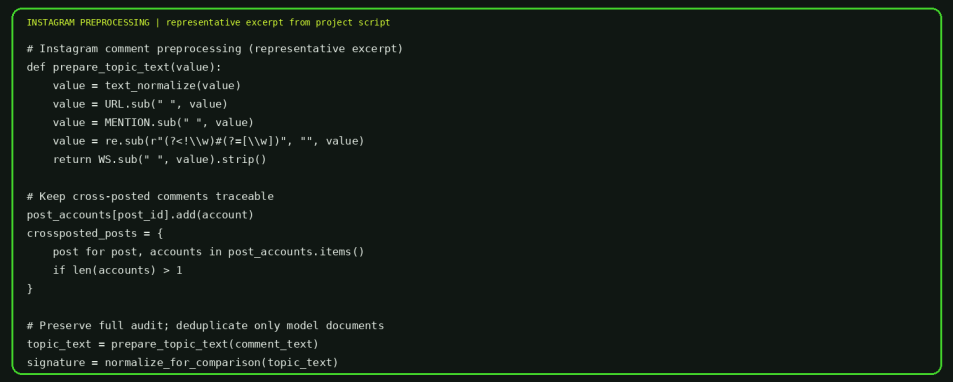

Figure 2. Representative preprocessing excerpt based on the project's Instagram cleaning script. The full script includes additional auditing and decision rules.

The Brand24 export contains 17,544 records; 9,484 have non-empty Content. Stage Final v2 produced 3,424 candidates and excluded 346, yielding 3,078 documents. Sources: Reddit 1,859; TikTok 754; Bluesky 396; Insider Razer 41; other 28. Dates: 23 August–23 September 2026.

Both corpora used BAAI’s BGE-base-en-v1.5 embeddings, UMAP, HDBSCAN and BERTopic. Settings: UMAP 30 neighbours/five dimensions; HDBSCAN minimum cluster size 25/minimum samples 5; seed 42. BGE reports a mean MTEB score of 63.55 across 56 datasets (BAAI, n.d.); BERTopic combines embeddings, density-based clustering and class-based TF-IDF (Grootendorst, 2022).

Topics were interpreted through keywords and representative samples. Instagram produced 74 non-outlier topics; its 8,532 English-candidate documents comprise 1,405 high-confidence English, 208 English-short and 6,919 recovered ambiguous-language items. Brand24 produced 20 machine topics consolidated into nine macro categories.

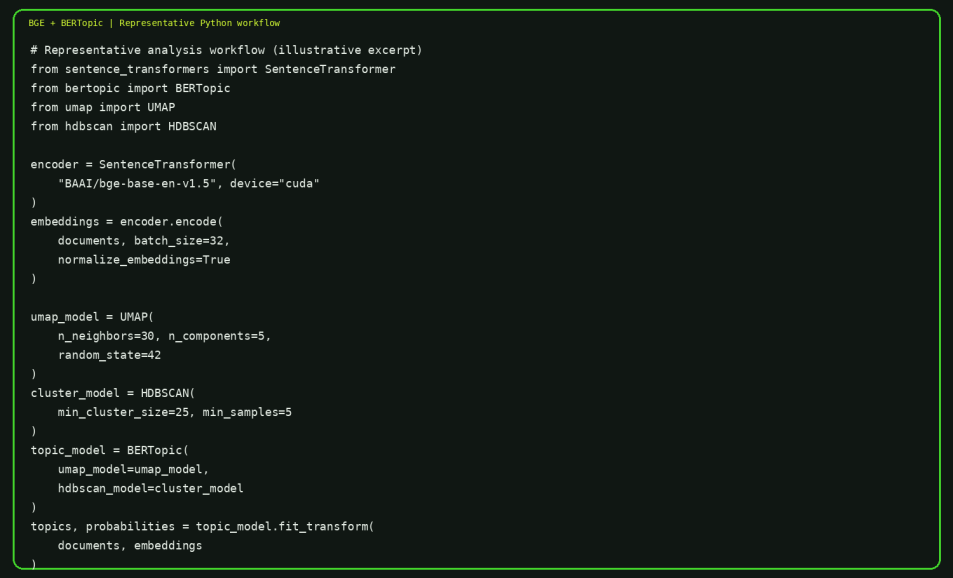

Figure 3. Representative Python workflow for BGE embedding and BERTopic fitting.

**Reproducible analysis — Corpus lineage and the modelling workflow**

The saved Instagram run uses v3.1 input, although the reusable training script retains
`v2` in its filename. Its metadata identifies the exact input hash. The pipeline is
text screening → language routing/recovery → normalized BGE embeddings → UMAP →
HDBSCAN → c-TF-IDF topic descriptions. Topic IDs belong to their own saved run and
must not be compared across the two corpora.

The cells below verify the retained language groups and display the original settings.
They do not refit the model during the default run. The initial Instagram cleaning
excerpt in Figure 2 is retained from the report; the local reconciliation and
language scripts cover the later stages available in the project folders.

In [2]:
language = ig.groupby("language_decision").size().rename("documents").to_frame()
assert language.documents.to_dict() == {"ENGLISH": 1405, "ENGLISH_SHORT": 208, "REVIEW_AMBIGUOUS": 6919}
display(language)
metadata = {name: json.loads((folder / "run_metadata.json").read_text(encoding="utf-8"))
            for name, folder in [("instagram", IG_RUN), ("brand24", BRAND24_RUN)]}
keys = ["embedding_model", "n_documents", "n_topics_excluding_outliers", "n_outliers",
        "umap_n_neighbors", "umap_n_components", "hdbscan_min_cluster_size",
        "hdbscan_min_samples", "random_seed", "input_sha256"]
display(pd.DataFrame({name: {key: meta.get(key) for key in keys} for name, meta in metadata.items()}))
display(pd.DataFrame({name: meta["versions"] for name, meta in metadata.items()}))

,documents
language_decision,
ENGLISH,1405
ENGLISH_SHORT,208
REVIEW_AMBIGUOUS,6919


,instagram,brand24
embedding_model,BAAI/bge-base-en-v1.5,BAAI/bge-base-en-v1.5
n_documents,8532,3078
n_topics_excluding_outliers,74,None
n_outliers,2715,701
umap_n_neighbors,30,30
umap_n_components,5,5
hdbscan_min_cluster_size,25,25
hdbscan_min_samples,5,5
random_seed,42,42
input_sha256,b2a7ab951fb49f12a2494a3d661155fe6f737849c541eff203b2643ef5e411f1,707a05bdaf7e30343190dec8e098eb24f85508dd6dc3940dccb99076843af83d


,instagram,brand24
torch,2.9.1+cu128,2.9.1+cu128
bertopic,0.17.4,0.17.4
sentence-transformers,6.2.0,6.2.0
umap-learn,0.5.12,0.5.12
hdbscan,0.8.44,0.8.44
scikit-learn,1.9.1,1.9.1
pandas,3.1.0,3.1.0


**Optional local Instagram screening and full model fitting**

Set `NMC5342_ROOT` to the local research folder if rerunning the Instagram stages.
Use a model environment matching the saved package versions above before enabling the flags.
The optional language-screening script also requires `lingua-language-detector==2.2.0`. This notebook contains no raw Instagram comments or per-document assignment tables. Fitting therefore requires the local text corpus. The original local scripts receive explicit paths below; outputs go to
`_razer_reproduction`, keeping the original research directories intact.

The training settings match the saved run. Cluster assignments can still vary with
dependency versions, hardware and numerical behavior; the aggregate checks in this
notebook refer to the saved original assignments. The original environment versions
are recorded above. BGE's quoted benchmark in the report is an external model-card
result, not an evaluation run by this notebook.

In [3]:
RUN_LOCAL_INSTAGRAM_SCREENING = False
RUN_FULL_MODELS = False
LOCAL_PROJECT = Path(os.environ["NMC5342_ROOT"]) if os.environ.get("NMC5342_ROOT") else PROJECT

if RUN_LOCAL_INSTAGRAM_SCREENING:
    if LOCAL_PROJECT is None:
        raise ValueError("Set NMC5342_ROOT to the local research folder first.")
    reviewed = LOCAL_PROJECT / "dataset/ins_comment/instagram_topic_modeling_reviewed.csv"
    subprocess.run([sys.executable, str(CODE / "prepare_instagram_english_v3.py"),
                    "--input", str(reviewed), "--output-dir", str(RUN / "language_v3")], check=True)
    subprocess.run([sys.executable, str(CODE / "recover_instagram_english_v31.py"),
                    "--input", str(RUN / "language_v3/instagram_language_audit_all.csv"),
                    "--output-dir", str(RUN / "language_v3_1")], check=True)
else:
    print("Optional local Instagram language screening is disabled.")

def fit_original_models(brand24_input):
    if LOCAL_PROJECT is None:
        raise ValueError("Set NMC5342_ROOT; raw Instagram text is required for model fitting.")
    ig_input = (RUN / "language_v3_1/instagram_topic_modeling_english_v31.csv"
                if RUN_LOCAL_INSTAGRAM_SCREENING else
                LOCAL_PROJECT / "dataset/ins_comment/language_v3_1/instagram_topic_modeling_english_v31.csv")
    for script, input_path, output in [
        ("run_bertopic_bge_v2.py", brand24_input, RUN / "brand24_refit"),
        ("run_bertopic_instagram_bge_v2.py", ig_input, RUN / "instagram_refit")]:
        if not input_path.is_file():
            raise FileNotFoundError(input_path)
        subprocess.run([sys.executable, str(CODE / script), "--input", str(input_path),
                        "--output-root", str(output), "--allow-cpu"], check=True)
print("Full model fitting is", "enabled; it will run after Brand24 cleaning" if RUN_FULL_MODELS else "disabled.")

Optional local Instagram language screening is disabled.
Full model fitting is disabled.


<a id="report-23"></a>

## 1. Social Media Audit and Strategic Objectives

<a id="report-24"></a>

### 1.1 Brand identity and Instagram account roles

Razer's main business is the sale of gaming products, such as mice, keyboards, laptops, chairs, and software. At the same time, it has established a complete ecosystem related to gaming through the gaming community culture, covering peripherals, Blade laptops, Synapse, Chroma, and Razer Gold (Razer, n.d.-a). Its audience often first comes into contact with the brand through e-sports events rather than the products themselves, and then gradually begins to understand the specific characteristics of its products.

This brand positioning has given Razer a dual identity. On the one hand, it is a gaming device brand which centered on product performance, technological innovation, and hardware sales. On the other hand, it is a cultural brand that encourages player engagement through e-sports partnerships, gaming culture, and community activities. These two identities mean that, in its social media communication, Razer must not only promote its products but also build emotional connections with audience through e-sports events, professional players and other gaming culture channels.

<a id="report-27"></a>

### 1.2 Platform Selection and Research Scope

To study the overall social media performance of Razer, we chose Instagram and TikTok as the main observation platforms, because these two platforms both focus on visual content and short videos, which align well with Razer's needs for product presentation and promotion of e-sports culture.

On Instagram the brand can present product features through images, short videos, and brand collaboration content. Moreover, the two accounts of Razer on Instagram, @razer and @teamrazer, have different communication positioning, providing a basis for comparing the interactions of product-oriented and e-sports culture-oriented audience.

TikTok, on the other hand, emphasizes short videos, creator participation, and entertainment expressions. By observing content in TikTok, we can analyze how Razer attracts viewers through gaming culture and creator content.

Therefore, this part uses Instagram comment data as the main source of analysis, while using qualitative observations from TikTok to supplement the understanding of Razer's social media communication strategies.

<a id="report-32"></a>

### 1.3 Current Social Media Communication

Razer’s social media communication mainly focuses on two directions.

Firstly, there is product-oriented communication. Razer releases products through its main account and presents the features and design highlights of the products, such as the Seiren V3 Pro microphone and the Kraken Kitty headphones. Also brand collaborations like the Razer × Sanrio Pudding Dog collaboration series extend this to the gaming lifestyle.

Secondly, there is the e-sports and gaming culture communication. Razer uses e-sports and gaming culture to build its brand, releasing content related to e-sports such as represents players, teams, and competitive events. At the same time, Razer also interacts with the gaming community through activities such as some events on Discord.

<a id="report-36"></a>

### 1.4 Strategic Objectives

Firstly, Razer needs to further strengthen the connection between product promotion and gaming culture. The brand can integrate product features, the usage scenarios of professional players, and gaming culture content to enhance the overall appeal of its campaign.

SMART Objective 1: Within three months after the implementation of the strategy, increase the average number of likes and comments by 15% on posts that combine Razer products with gaming culture on social media.

Secondly, Razer needs to pay more attention to consumers' negative feedback and the brand's response. The initial Brand24 data shows that the brand has a relatively high rate of negative comments. These negative comments not only reflect the actual needs of consumers but may also affect brand trust.

SMART Objective 2: Within three months after the strategic implementation, ensure that at least 80% of the identifiable and solvable negative comments related to Razer can receive an official response within 48 hours.

<a id="report-42"></a>

## 2. Target Audience and Community Discourse

<a id="report-43"></a>

### 2.1 Target Audience Overview

Razer is a brand that combines gaming products and gaming culture. Therefore, its target audience is not only the purchasers of gaming devices, but also the community participants who are interested in e-sports, game streamers, and gaming culture.

Since this part mainly relies on qualitative observations of social media content to do the analysis, it is hard to directly confirm the age, income, or other demographic characteristics of the users. Therefore, we adopted an audience segmentation method based on interests and participation motivations.

Based on the analysis, we have identified two different segments of audience. Consumers oriented towards product performance pay more attention to specifications, prices, availability, connectivity, and a use-case fit, while enthusiasts of e-sports and gaming culture focus more on teams, players, events, and collaboration projects.

<a id="report-47"></a>

### 2.2 Key Audience Segments

Segment A: Product-Oriented Consumers

This group mainly focuses on the value of the gaming devices themselves, such as performance, price, product quality and actual usage experience. They might be current users of Razer products or potential consumers who are familiar with different brand devices. Social media content can help them access new product information, understand product specifications, compare device performance, and even assist them to make purchasing decisions.

Segment B: Gaming Culture and E-sports Fans

This group pays more attention to games and e-sports events. Their interest in Razer often stems from e-sports players, teams, events, game streamers, and related brand collaborations. They may not be actual purchasers of Razer products, but they might establish emotional connections with the brand by continuously following e-sports events. Compared to product-oriented consumers, this type of audience is more likely to be attracted by game culture content and community interaction. For them, the value of the brand lies not only in the product performance, but also in the culture and story behind the brand.

Moreover, these two demands are not contradictory. The devices used by professional players may arouse the interest of e-sports fans, while the positive product experience of consumers may also enhance their identification with the Razer community culture.

<a id="report-54"></a>

## 3. What Works: Content, Engagement and Audience Response

<a id="report-55"></a>

### 3.1 From brand content to audience response

There is a natural connection between the brand content and the discussions among the audience. A product launch might raise questions about supply conditions and a marketing campaign might attract criticism of its content. Likes, comments, and shares reflect different motivations for participation (Swani & Labrecque, 2020). Therefore, through thematic analysis, we can identify the most core responses of the brand's audience to the brand's content.

Out of a total of 8,532 documents, 5,817 were assigned to 74 non-abnormal topics (68.18%), while 2,715 could not be categorized. And 816 comments were of mixed topics. Among all the topics, market availability accounted for the largest proportion (262 comments), followed by gaming mice (218), keyboards (186), gaming chairs (147), and headphones/microphones (145). Other smaller clusters include price (91 comments), preference for wired/wireless (69 comments), and white version (47 comments).

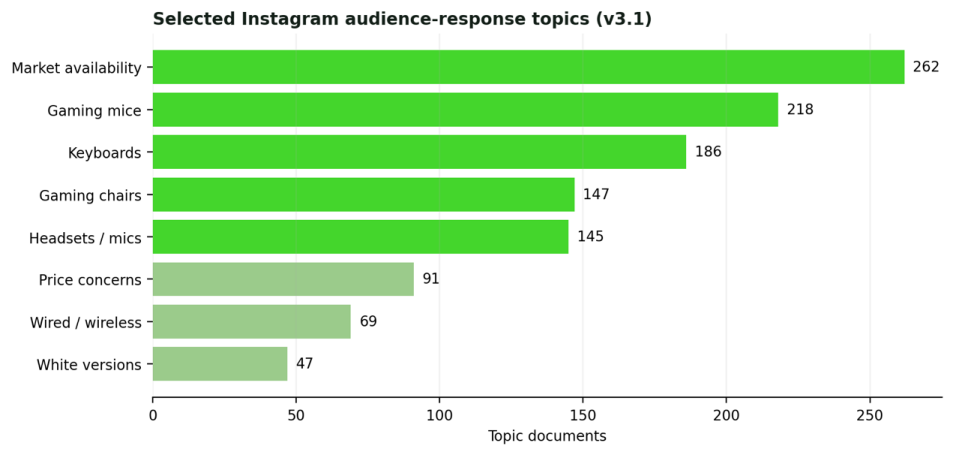

Figure 4. Selected Instagram topic counts. Counts represent documents assigned to individual model topics.

**Reproducible analysis — Instagram topic sizes (Figure 4)**

The display names below are interpretive labels from the report. Counts come from saved machine assignments. Outliers remain in the denominator.

Assigned: 5,817/8,532 (68.18%); outliers: 2,715.


,Topic,label,documents
0,1,Market availability,262
1,3,Gaming mice,218
2,4,Keyboards,186
3,7,Gaming chairs,147
4,8,Headsets / microphones,145
5,17,Price,91
6,24,Wired / wireless,69
7,39,White versions,47


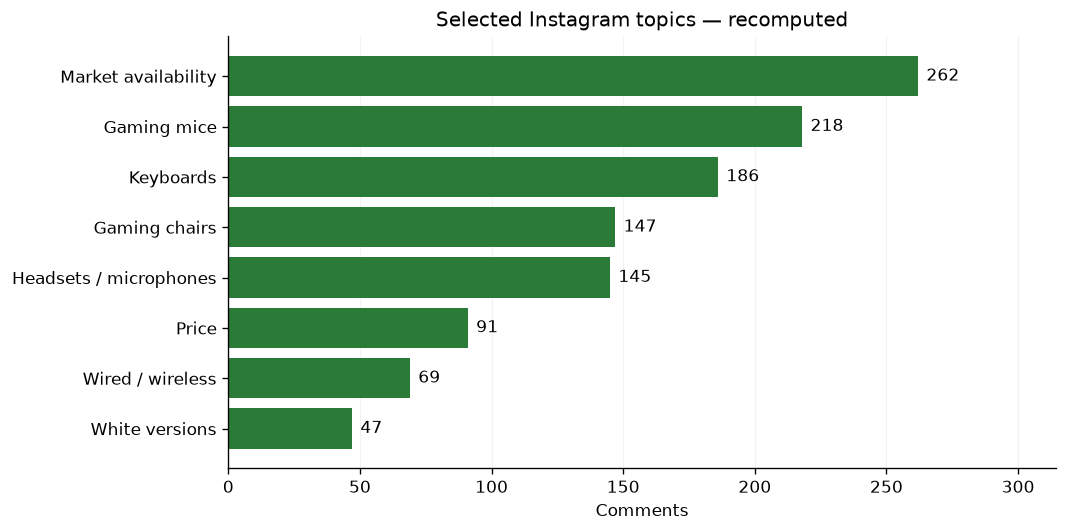

In [4]:
topic_counts = ig.groupby("Topic").size()
assert len(topic_counts.drop(index=-1)) == 74
assert topic_counts[-1] == 2715 and topic_counts[0] == 816
assigned = int(ig.Topic.ne(-1).sum())
assert assigned == 5817
print(f"Assigned: {assigned:,}/{len(ig):,} ({100*assigned/len(ig):.2f}%); outliers: {topic_counts[-1]:,}.")
labels = {1: "Market availability", 3: "Gaming mice", 4: "Keyboards", 7: "Gaming chairs",
          8: "Headsets / microphones", 17: "Price", 24: "Wired / wireless", 39: "White versions"}
products = pd.DataFrame([{"Topic": t, "label": label, "documents": int(topic_counts[t])}
                         for t, label in labels.items()])
assert products.documents.tolist() == [262, 218, 186, 147, 145, 91, 69, 47]
display(products)
horizontal_chart(products, "label", "documents", "Selected Instagram topics — recomputed", "Comments")

These topic distributions indicate that Razer's product promotion not only attracts consumers' attention but also prompts them to raise more specific questions regarding purchase and usage, especially regarding market supply, prices, and product configurations. This indicates that some users hope to obtain information that can support their decision-making process for purchase through social media.

<a id="report-61"></a>

### 3.2 Product demand and e-sports community response

Meanwhile, there were significant differences between the @razer and @teamrazer accounts in the two topics of e-sports and fan support, namely Topic 12 and Topic 30. These two topics contained a total of 165 comments. Under the @razer account, 7,901 comments included 8 belonging to these two groups (0.10%), while under the @teamrazer account, 559 comments included 154 belonging to these two groups (27.55%). The difference between the two was 27.45 percentage points.

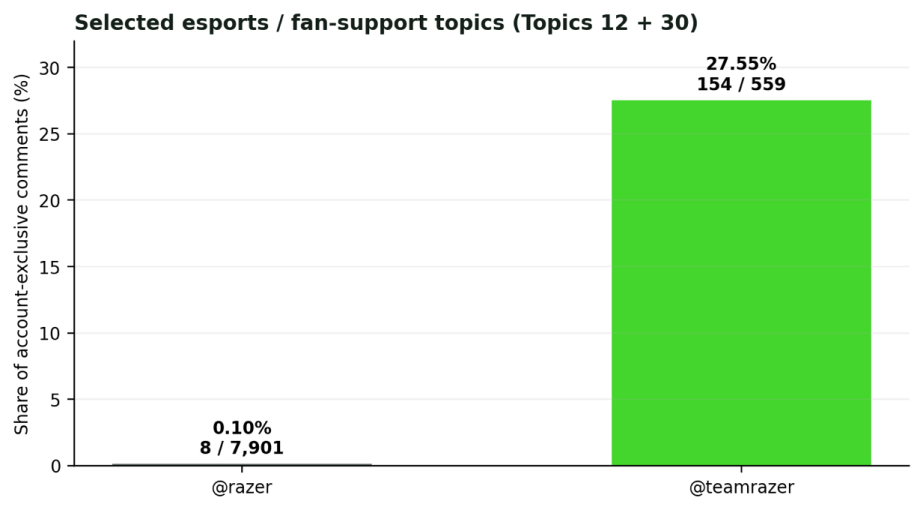

Figure 5. Share of comments in selected e-sports/fan-support topics by account-exclusive corpus.

**Reproducible analysis — Account-exclusive fan-support shares (Figure 5)**

Shared-post comments are a separate group and are excluded from both account-exclusive denominators.

,documents,fan_comments,share_percent
account_scope,,,
razer,7901,8,0.10
shared,72,3,4.17
teamrazer,559,154,27.55


Fan-topic comments: 165; exclusive-account gap: 27.45 percentage points.


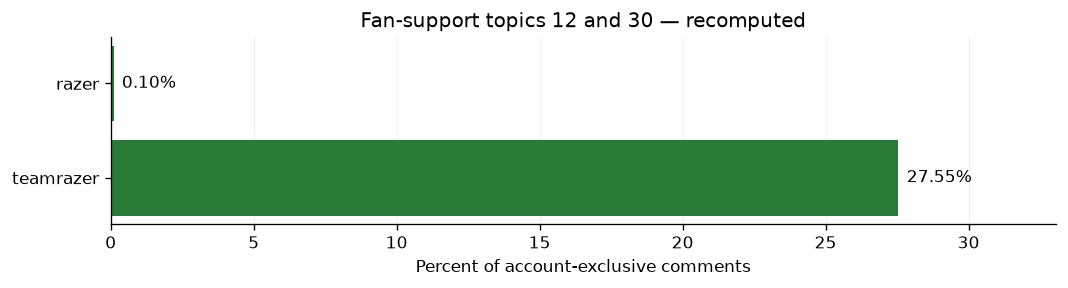

In [5]:
fans = ig.assign(fan_support=ig.Topic.isin([12, 30])).groupby("account_scope").agg(
    documents=("document_key", "size"), fan_comments=("fan_support", "sum"))
fans["share_percent"] = 100 * fans.fan_comments / fans.documents
assert fans.documents.to_dict() == {"razer": 7901, "shared": 72, "teamrazer": 559}
assert fans.fan_comments.to_dict() == {"razer": 8, "shared": 3, "teamrazer": 154}
gap_pp = fans.loc["teamrazer", "share_percent"] - fans.loc["razer", "share_percent"]
assert round(gap_pp, 2) == 27.45
display(fans)
print(f"Fan-topic comments: {fans.fan_comments.sum()}; exclusive-account gap: {gap_pp:.2f} percentage points.")
horizontal_chart(fans.loc[["razer", "teamrazer"]].reset_index(), "account_scope", "share_percent",
                 "Fan-support topics 12 and 30 — recomputed", "Percent of account-exclusive comments", percent=True)

This difference indicates that although the two Instagram accounts of Razer belong to the same brand, they play distinctly different roles in the audience discussions. This difference is consistent with the content positioning of the two accounts. @razer covers product-related content, while @teamrazer focuses more on the community culture formed around professional players, teams, and events. According to the Brand-Community Theory, shared consciousness, rituals and responsibility among community members are important foundations for the formation of a brand community (Muniz & O’Guinn, 2001). Therefore, e-sports content not only can attract attention for the brand, but also may enhance the audience's sense of belonging through shared experiences their fan identities within the community.

<a id="report-66"></a>

### 3.3 Creative authenticity and content effectiveness

The third response pattern is the discussion of the authenticity of the creativity. Topic 2 contains 228 critical comments on AI creation content, and Topic 73 contains 25 unfollow/rejection comments. Together, these two account for 253 comments (2.97% of the total) in the corpus, of which 133 (52.57%) are related to single post.

**Reproducible analysis — AI-creative criticism and post concentration**

In [6]:
ai_comments = ig[ig.Topic.isin([2, 73])]
per_post = ai_comments.groupby("post_key").size().sort_values(ascending=False)
assert len(ai_comments) == 253 and int(per_post.iloc[0]) == 133
display(ai_comments.groupby("Topic").size().rename("documents").to_frame())
print(f"Share of all comments: {100*len(ai_comments)/len(ig):.2f}%")
print(f"Largest post: {per_post.iloc[0]} comments; {100*per_post.iloc[0]/len(ai_comments):.2f}% of these two topics.")

,documents
Topic,
2,228
73,25


Share of all comments: 2.97%
Largest post: 133 comments; 52.57% of these two topics.


This result indicates that consumers' evaluations of brand content extend beyond the product itself and also cover the creation process of the content. Razer emphasizes gaming culture, so its audience may expect the brand content to reflect an understanding of game creators, artistic expression, and community culture. When marketing activities are perceived to rely excessively on AI-generated content, some users may consider this as a sign of the brand lacking creative input or neglecting the value of creators.

Furthermore, from the analysis results, we can see that a high number of comments does not necessarily indicate positive interaction. Controversial content can also receive a lot of attention, but this causes great harm to the audience's trust in the brand itself.

Overall, the social media content of Razer mainly elicited three different types of responses from its audience, product-related content prompted users to express actual purchase and usage needs, e-sports-related content supported fans' participation and community identification, while creative marketing content might trigger discussions about the brand's authenticity and creative approach. These results indicate that the effectiveness of different social media interactions cannot be judged solely by the number of interactions, but should be evaluated in conjunction with their communication goals and the specific nature of the audience's responses.

However, the comments under the official brand accounts can only reflect the responses of a portion of the audience. In order to gain a deeper understanding of the product experiences and negative discussions of consumers in a broader online environment, the next part will combine Brand24's social listening data to analyze the main consumer concerns faced by Razer.

<a id="report-73"></a>

## 4 Social listening and audience problem identification

<a id="report-74"></a>

### 4.1 Brand24 corpus screening and sample composition

Brand24 extends the scope of analysis beyond Razer’s owned accounts. Brand24's original row-level export contains a total of 17,544 records. After eliminating 8,060 records with empty text or only whitespace, 9,484 non-empty records remained. After further screening, Stage Final v2 yielded 3,424 records. Then, 346 were excluded.

The contents of the excluded 346 records include 110 records with only labels or less substantive information, 101 second-hand transaction information, 46 DC Green Lantern-related content, 32 razor-related content, 16 preferential robot posts, and 15 electric vehicle or motorcycle-related content. The focus of the screening is to remove the mismatch of the same name and low-information content, so that the analysis focuses on the substantive discussion related to Razer.

After screening, 3,078 records were included in the analysis. The documents cover August 23 to September 23, 2026, and came from Reddit (1,859), TikTok (754), Bluesky (396), Insider Razer (41), and other sources (28).

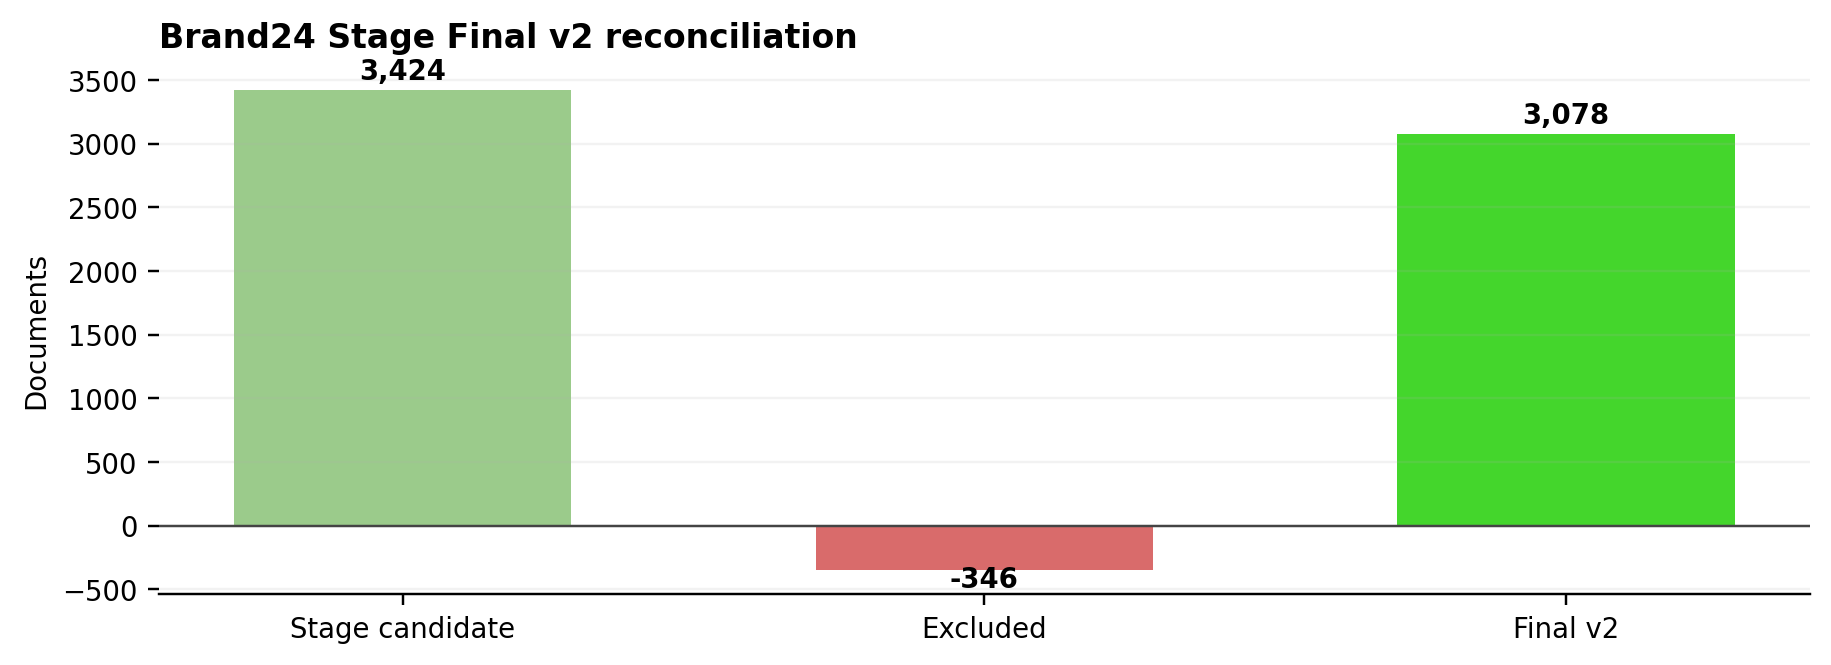

Figure 6. Record counts from the candidate corpus to the final corpus

**Reproducible analysis — Brand24 export, screening and sources (Figure 6)**

The next cell runs the original Stage Final v2 cleaner on the 3,424-row candidate
file in the local research folder. It verifies the retained record IDs against
the saved model assignments. Exclusion rules can overlap. The code displays the
original nonexclusive rule counts, which use a different counting convention from
the narrative's selected exclusion categories. No synthetic category counts are added.

Fresh Stage Final v2 run: 3,424 candidates → 346 exclusions → 3,078 retained; IDs match the saved run.


,stage,documents
0,Row-level export,17544
1,Non-empty content,9484
2,Candidate corpus,3424
3,Final corpus,3078


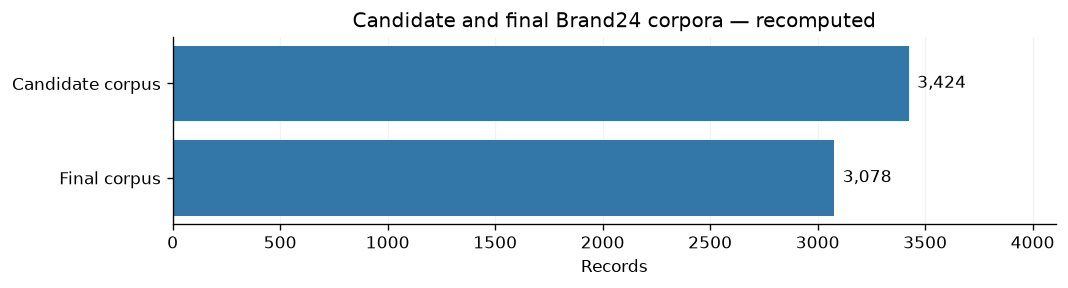

,nonexclusive_rule_matches
v2_exclusion_reason,
hashtag_only_without_substance,119
classified_marketplace_listing,101
dc_lantern_character,46
shaving_razor,33
price_feed_or_deal_bot,19
ebike_motorsport_homonym,15
idiom_or_spelling,8
nonbrand_popculture_or_robot,6
motorola_razr,5


,documents
Domain,
reddit.com,1859
tiktok.com,754
bsky.app,396
insider.razer.com,41
steamcommunity.com,12
linkedin.com,5
github.com,4
ozbargain.com.au,2
forum.square-enix.com,1


Final corpus dates: 2026-08-23 to 2026-09-23


In [7]:
workbook = PROJECT / "dataset/razer_report_2026-09-24_04.52 (1).xlsx"
raw = pd.read_excel(workbook, sheet_name="Mentions", header=1)
nonempty = raw.loc[raw.Content.fillna("").astype(str).str.strip().ne("")].copy()
assert len(raw) == 17544 and len(nonempty) == 9484
candidate_path = PROJECT / "dataset/stage_final/razer_stage_final.csv"
candidates = pd.read_csv(candidate_path, dtype={"ID": "string"}, low_memory=False)
assert len(candidates) == 3424
result = subprocess.run([sys.executable, str(CODE / "clean_razer_stage_final_v2.py"),
                         "--input", str(candidate_path), "--output-dir", str(RUN / "brand24_cleaning")],
                        check=True, capture_output=True, text=True, encoding="utf-8")
clean_path = RUN / "brand24_cleaning/razer_stage_final_v2.csv"
cleaned = pd.read_csv(clean_path, dtype={"ID": "string"}, low_memory=False)
excluded = pd.read_csv(RUN / "brand24_cleaning/razer_exclusion_audit_v2.csv", low_memory=False)
assert len(cleaned) == 3078 and len(excluded) == 346
assert set(cleaned.ID) == set(brand24.ID)
print("Fresh Stage Final v2 run: 3,424 candidates → 346 exclusions → 3,078 retained; IDs match the saved run.")
screening = pd.DataFrame({"stage": ["Row-level export", "Non-empty content", "Candidate corpus", "Final corpus"],
                           "documents": [len(raw), len(nonempty), len(candidates), len(cleaned)]})
display(screening)
horizontal_chart(screening.iloc[2:], "stage", "documents", "Candidate and final Brand24 corpora — recomputed", "Records", color=BLUE)
display(excluded.v2_exclusion_reason.str.split(";").explode().value_counts().rename("nonexclusive_rule_matches").to_frame())
sources = brand24.Domain.value_counts()
assert sources.loc[["reddit.com", "tiktok.com", "bsky.app", "insider.razer.com"]].tolist() == [1859, 754, 396, 41]
assert int(sources.iloc[4:].sum()) == 28
display(sources.rename("documents").to_frame())
dates = pd.to_datetime(brand24.Date)
print("Final corpus dates:", dates.min().date(), "to", dates.max().date())
if RUN_FULL_MODELS:
    fit_original_models(clean_path)

<a id="report-80"></a>

### 4.2 Negative-label baseline and topic structure

Figure 7 shows the summary results of the Brand24 dashboard and the screening results of the exported corpus side by side. The proportion of negative labels recorded on the dashboard was 12.42% (2,191/17,637). The proportion in the original row-level export was 9.90% (1,737/17,544). Among records with non-empty text, the proportion was 7.77% (737/9,484). In the final corpus, the proportion was 18.10% (557/3,078).

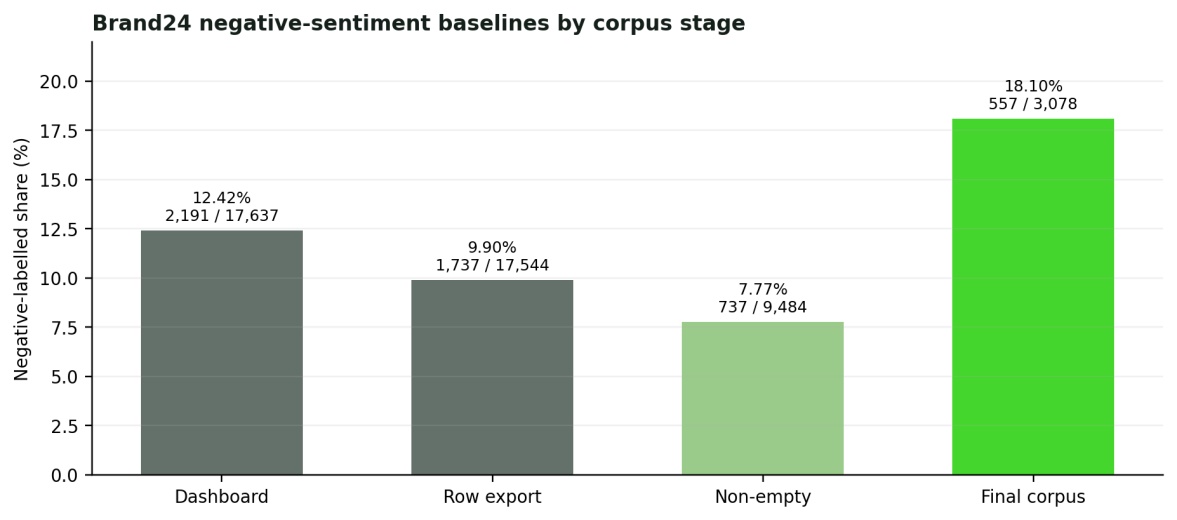

Figure 7. Negative-label rates in the Brand24 dashboard, row-level export, non-empty records, and final corpus

**Reproducible analysis — Four negative-label baselines (Figure 7)**

The dashboard totals are read from the workbook's Analytics data sheet. These are different selection scopes, not a time series. A negative label is the original Brand24 value −1, not a newly inferred or human-verified sentiment.

,scope,negative,documents,negative_percent,final_minus_scope_pp
0,Dashboard,2191,17637,12.42,5.67
1,Row-level export,1737,17544,9.90,8.20
2,Non-empty content,737,9484,7.77,10.33
3,Final corpus,557,3078,18.10,0.00


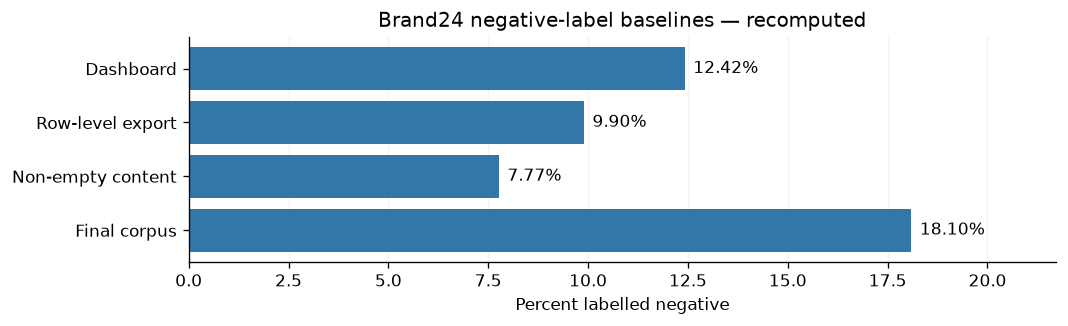

In [8]:
analytics = pd.read_excel(workbook, sheet_name="Analytics data").set_index("Metric")["Value"]
baselines = pd.DataFrame([
    ["Dashboard", int(analytics["Number of Negatives"]), int(analytics["Mentions"])],
    ["Row-level export", int(raw.Sentiment.eq(-1).sum()), len(raw)],
    ["Non-empty content", int(nonempty.Sentiment.eq(-1).sum()), len(nonempty)],
    ["Final corpus", int(brand24.Sentiment.eq(-1).sum()), len(brand24)],
], columns=["scope", "negative", "documents"])
assert baselines.negative.tolist() == [2191, 1737, 737, 557]
assert baselines.documents.tolist() == [17637, 17544, 9484, 3078]
baselines["negative_percent"] = 100 * baselines.negative / baselines.documents
baseline_percent = float(baselines.iloc[-1].negative_percent)
baselines["final_minus_scope_pp"] = baseline_percent - baselines.negative_percent
display(baselines)
horizontal_chart(baselines, "scope", "negative_percent", "Brand24 negative-label baselines — recomputed",
                 "Percent labelled negative", color=BLUE, percent=True)

BERTopic identified 20 topics, which were grouped into nine macro-topics. The document counts were 480 for gaming mice, 432 for audio and streaming, 320 for laptops and PC setups, 295 for culture and creators, 281 for keyboards, 241 for controllers and mobile, 197 for software and compatibility, 96 for accounts and payments, and 35 for gaming furniture. There are also 701 unassigned documents.

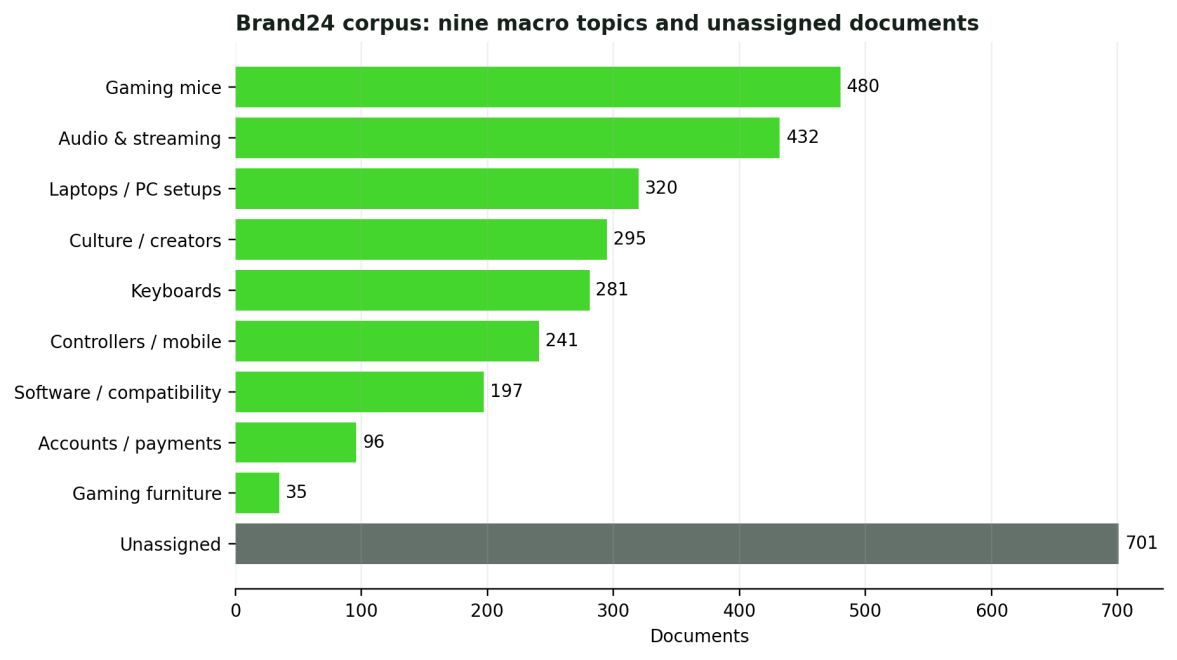

Figure 8. Nine macro-topics and unassigned documents

**Reproducible analysis — Twenty machine topics to nine macro-topics (Figure 8)**

The original local project mapping is applied again and checked row by row. Macro-topic names are interpretive groupings; the outlier group is retained separately.

,macro_topic_code_auto,macro_topic_label_auto,documents,share_percent
0,M01,Gaming Mice,480,15.59
1,M02,Audio & Streaming Peripherals,432,14.04
2,M03,Keyboards & Keypads,281,9.13
3,M04,Software & Compatibility,197,6.40
4,M05,Gaming Laptops & PC Setups,320,10.40
5,M06,Controllers & Mobile Gaming,241,7.83
6,M07,"Accounts, Payments & Gift Cards",96,3.12
7,M08,Gaming Furniture,35,1.14
8,M09,"Brand Culture, Creators & Collaborations",295,9.58
9,UNASSIGNED,Unassigned / Outlier,701,22.77


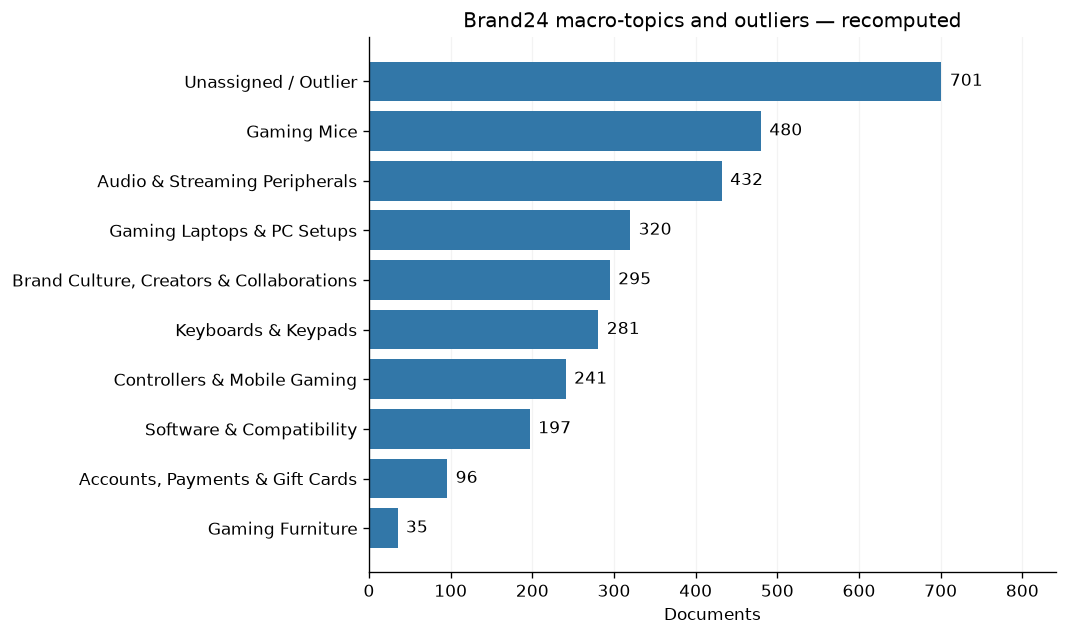

In [9]:
spec = importlib.util.spec_from_file_location("razer_macro_original", CODE / "build_razer_macro_topics_100.py")
macro_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(macro_module)
mapped = brand24.Topic.map(macro_module.TOPIC_TO_MACRO)
assert mapped.notna().all() and mapped.equals(brand24.macro_topic_code_auto)
assert brand24.loc[brand24.Topic.ne(-1), "Topic"].nunique() == 20
macros = brand24.groupby(["macro_topic_code_auto", "macro_topic_label_auto"]).size().rename("documents").reset_index()
assert dict(zip(macros.macro_topic_code_auto, macros.documents)) == {
    "M01": 480, "M02": 432, "M03": 281, "M04": 197, "M05": 320,
    "M06": 241, "M07": 96, "M08": 35, "M09": 295, "UNASSIGNED": 701}
macros["share_percent"] = 100 * macros.documents / len(brand24)
display(macros)
horizontal_chart(macros.sort_values("documents", ascending=False), "macro_topic_label_auto", "documents",
                 "Brand24 macro-topics and outliers — recomputed", "Documents", color=BLUE)

Two team members manually coded a shared sample. Cohen’s κ was 0.488 for content type (n = 100), 0.838 for macro-topic (n = 56), and 0.432 for sentiment polarity (n = 56). Intercoder agreement was highest for macro-topic and lowest for sentiment polarity.

**Reproducible analysis — Intercoder agreement**

The three κ values above are preserved as reported group results. The local reviewer
workbooks found in the project are blank coding templates, so they cannot independently
reproduce those values. The function below computes unweighted Cohen's κ from paired,
completed labels without fabricating annotations. To run it, provide a CSV with
`Sample_ID`, `coder_a` and `coder_b`, already restricted to the appropriate analysis
subset (100 content-type cases or 56 macro-topic/sentiment cases).

In [10]:
def cohen_kappa(labels_a, labels_b):
    paired = pd.DataFrame({"a": labels_a, "b": labels_b}).replace(r"^\s*$", pd.NA, regex=True).dropna()
    if len(paired) == 0:
        raise ValueError("No paired completed labels.")
    observed = float(paired.a.eq(paired.b).mean())
    pa = paired.a.value_counts(normalize=True)
    pb = paired.b.value_counts(normalize=True)
    expected = float(pa.mul(pb, fill_value=0).sum())
    if expected == 1:
        raise ValueError("Kappa is undefined when expected agreement is 1.")
    return {"n": len(paired), "observed_agreement": observed,
            "expected_agreement": expected, "kappa": (observed - expected) / (1 - expected)}

completed_review_csv = os.environ.get("NMC5342_PAIRED_CODING_CSV")
if completed_review_csv:
    labels = pd.read_csv(completed_review_csv, dtype="string")
    assert labels.Sample_ID.is_unique
    display(pd.Series(cohen_kappa(labels.coder_a, labels.coder_b)))
else:
    display(pd.DataFrame({"dimension": ["Content type", "Macro-topic", "Sentiment polarity"],
                          "reported_n": [100, 56, 56], "reported_kappa": [.488, .838, .432],
                          "status": ["Reported in Word; not recomputed from completed coding"] * 3}))

,dimension,reported_n,reported_kappa,status
0,Content type,100,0.49,Reported in Word; not recomputed from completed coding
1,Macro-topic,56,0.84,Reported in Word; not recomputed from completed coding
2,Sentiment polarity,56,0.43,Reported in Word; not recomputed from completed coding


<a id="report-88"></a>

### 4.3 What issues appear in negative discussions?

This section selects the three topics of Synapse/software, accounts/payments, and headsets/audio for analysis. The negative-label rates for all three topics exceeded the final corpus baseline of 18.10%. Together, the three topics contained 606 records, accounting for 19.69% of the final corpus. Of these, 256 were labeled negative, accounting for 45.96% of all negatively labeled documents in the final corpus. The negative-label rate for Synapse/software was 57.87% (114/197), 39.77 percentage points above the baseline. For accounts/payments, it was 36.46% (35/96), 18.36 percentage points above the baseline. For headsets/audio, it was 34.19% (107/313), 16.09 percentage points above the baseline. The discussion below examines the problems users reported in these three areas.

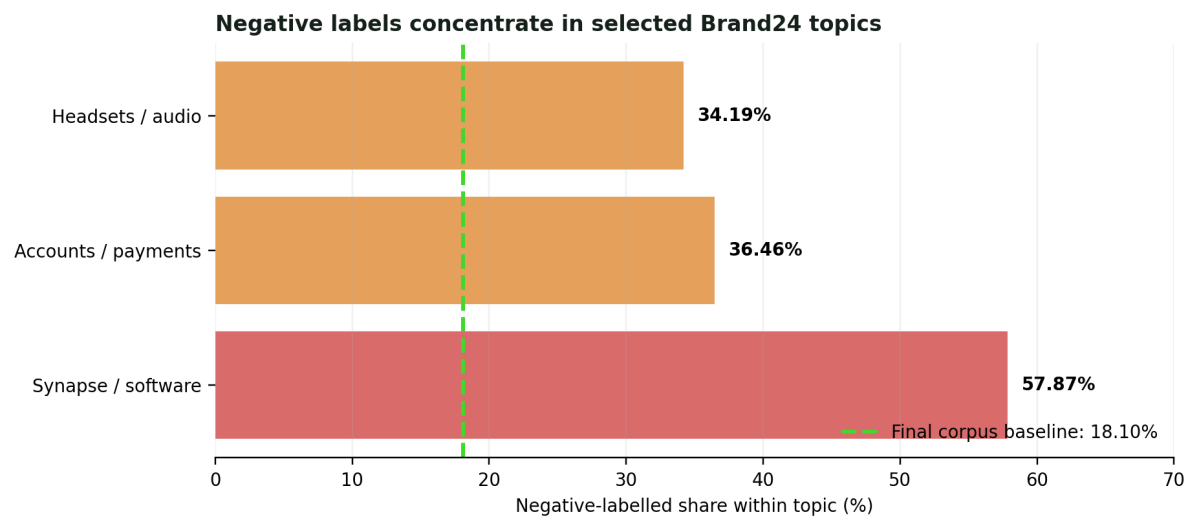

Figure 9. Negative-label rates in selected original topic clusters

**Reproducible analysis — Priority negative topics and percentage-point gaps (Figure 9)**

These are original machine topics 4, 8 and 1. In particular, the 313-document headset topic is narrower than the 432-document audio macro-topic.

,Topic,label,documents,negative,negative_percent,pp_above_final
0,4,Synapse / software,197,114,57.87,39.77
1,8,Accounts / payments,96,35,36.46,18.36
2,1,Headsets / audio,313,107,34.19,16.09


Combined: 606 documents (19.69% of final corpus)
Negative: 256 (45.96% of all negative labels)


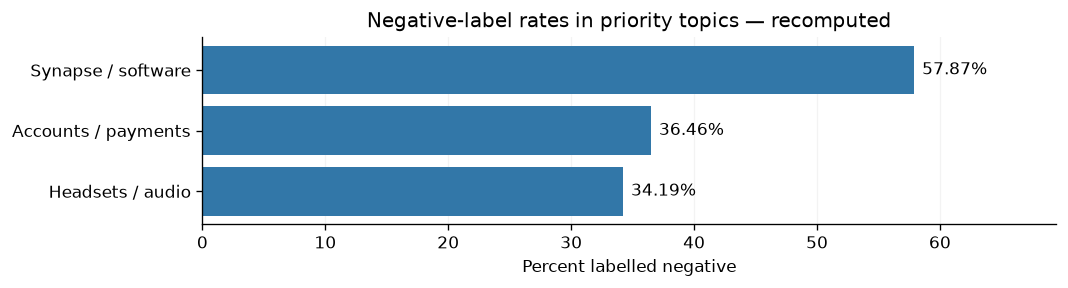

In [11]:
priority_rows = []
for topic, label in [(4, "Synapse / software"), (8, "Accounts / payments"), (1, "Headsets / audio")]:
    part = brand24.loc[brand24.Topic.eq(topic)]
    negative = int(part.Sentiment.eq(-1).sum())
    rate = 100 * negative / len(part)
    priority_rows.append([topic, label, len(part), negative, rate, rate - baseline_percent])
priority = pd.DataFrame(priority_rows, columns=["Topic", "label", "documents", "negative", "negative_percent", "pp_above_final"])
assert priority.documents.tolist() == [197, 96, 313]
assert priority.negative.tolist() == [114, 35, 107]
assert priority.pp_above_final.round(2).tolist() == [39.77, 18.36, 16.09]
display(priority)
print(f"Combined: {priority.documents.sum()} documents ({100*priority.documents.sum()/len(brand24):.2f}% of final corpus)")
print(f"Negative: {priority.negative.sum()} ({100*priority.negative.sum()/brand24.Sentiment.eq(-1).sum():.2f}% of all negative labels)")
horizontal_chart(priority, "label", "negative_percent", "Negative-label rates in priority topics — recomputed",
                 "Percent labelled negative", color=BLUE, percent=True)

The software topic involves Windows, installation, drivers and updates. A Reddit post describes how login failure affects the use of peripherals. Razer can make installation, update and offline usage guidelines according to product and software version, and provide corresponding troubleshooting steps and links to customer support in the tutorial.

The discussion of headsets involves sound quality, microphone performance, wireless connection, comfort and compatibility. For buyers, Razer can use microphone recordings and feature comparisons to explain the product differences. For existing users, connection and compatibility guidelines can be provided, and fault reports can be transferred to technical support. 

Account and payment discussions involve account access, payment services and third-party fraud. For example, a post mentioned Razer-related payment when describing a fraud related to account retrieval. For account access or payment issues, Razer can provide the corresponding official support portal. For fraud-related discussions, payment security tips can be issued to help users identify suspicious activity and verify official service channels.

Analyzing specific posts helps Razer understand what additional product information users need to supplement, which difficulties they encounter in use, and what problems need to be followed up by customer service or the technical team. Razer can update the product description and troubleshooting guide according to these findings, and provide a clear support entrance so that users can find the information they need or get help faster.

<a id="report-96"></a>

## 5 Competitive and cross-industry qualitative benchmarking

<a id="report-97"></a>

### 5.1 Benchmark selection and analysis methods

This section selects Logitech G, Secretlab and Red Bull as three types of benchmarks. Logitech G competes directly with Razer in core peripheral categories such as mice, keyboards and headsets. Secretlab focuses on gaming chairs and desk systems and competes with Razer for spending on gaming setups. Its gaming chairs compete directly with the Razer Iskur line. Red Bull serves as an aspirational benchmark. The analysis examines how Oracle Red Bull Racing produces content around races, drivers and technology.

<a id="report-99"></a>

### 5.2 How Logitech G and Razer explain product performance

Logitech Group's Gaming category achieved sales of about $1.338 billion in fiscal year 2025, an increase of 9% over the previous fiscal year (Logitech International S.A., 2025). Brand24 discussions show that players compare the lift-off distance of the Razer Viper Pro and Logitech G PRO X SUPERLIGHT. They also pay attention to the wireless connection of the headphones, microphone performance, as well as the noise and feel of the keyboard. These discussions show that when players buy, they want to know how the performance differences of different products affect actual use. Brands can help players judge which product is more suitable for their usage habits through function demonstrations and comparisons based on testing.

In its product introductions, Logitech G explains how professional players participate in product development. Through its Designed with Pros initiative, Logitech G uses player feedback and testing to understand the needs of competitive players (Logitech G, n.d.). In a video about the PRO X SUPERLIGHT 2 on its official YouTube channel, the Logitech G team explained the product with the e-sports players (Logitech G, 2023). During the IEM Beijing in 2026, Logitech G acted as an official peripheral partner and gained brand display opportunities in some competition broadcasts. The cooperation also included setting up an experience area in the venue so that the audience could try the products (ESL FACEIT Group, 2026). This content helps players understand how the functions are designed and how the devices are used in competition.

Razer published a carousel celebrating MOUZ’s victory after IEM Beijing, congratulating the team and mentioning Razer’s keyboard (Razer, 2026c). The Razer Viper V3 Pro Faker Edition video on its official YouTube channel shows the mouse created in collaboration with Faker (Razer, 2025). These samples show that Razer is good at putting products into the familiar e-sports context of players through the stories of players and teams. Logitech G’s in-depth product video complements this approach by showing how a specific function connects player needs, product design and actual use.

Razer can choose a function with a clear use case from the Razer NiKo Collection (Razer, 2026a) or a team partnership and build a video around a purchase question raised on social media. For example, Razer could ask a player to explain when mouse lift-off distance matters and then demonstrate what happens when the mouse is lifted and set down at two different settings. In this way, the player's story can not only attract attention, but also help players understand how the function affects their operation.

<a id="report-104"></a>

### 5.3 How Secretlab and Razer present gaming setups

Secretlab focuses on gaming chairs and desks, including TITAN Evo and MAGNUS, and emphasizes ergonomics, long-term use and professional e-sports environment (Secretlab, n.d.). In its MAGNUS Metal Desk Demo Guide video on YouTube, Secretlab shows how to organize cables, install a monitor arm and adjust a chair within the same desk setup (Secretlab, 2021). The audience can see what problems these products solve in a desk setup, and players can also imagine what the products look like after they are put on their desktops.

Razer already has content showing individual features and how products fit together. Its Iskur V2 NewGen video focuses on how sitting posture changes throughout the day and shows how the chair’s lumbar support adjusts accordingly (Razer, 2026b). Razer’s Xbox anniversary Instagram clip shows the Basilisk mouse and BlackWidow keyboard under the same theme (Razer, 2026d). Razer has been able to explain individual product features and present multiple peripherals under a shared co-branded theme. Secretlab’s example shows how several products can work together to solve a practical problem.

Razer can use a real desk setup to demonstrate configuration choices for long gaming sessions. For example, first present the sitting posture or desktop layout problems encountered by players, and then show how to adjust the chair, how to position the mouse and keyboard, and how to match the lighting and software settings. Each product has a visible use, and the audience can also find a step suitable for themselves to copy from the whole set of demonstrations.

<a id="report-108"></a>

### 5.4 How Red Bull Racing and Razer extend event coverage

Red Bull provides fans with several ways to follow the same event. For the 2026 São Paulo Grand Prix, Oracle Red Bull Racing produced a track preview, a short post-race video and a race recap with audience Q&A. Before the race, the team used sim racing to introduce viewers to the Interlagos circuit in its Oracle Virtual Laps series on YouTube (Oracle Red Bull Racing, 2026c). After the race, the team posted a short video on Instagram highlighting how Verstappen started 21st on the grid and finished second (Oracle Red Bull Racing, 2026a). The next day, the team reviewed his progress through the field on its YouTube show Talking Bull and answered audience questions later in the episode (Oracle Red Bull Racing, 2026b).

Razer can also use the same player to connect product release and fan participation. Razer’s YouTube video for the Faker Edition introduces the co-branded mouse (Razer, 2025), and its 2026 Instagram announcement featuring Faker explains how fans can take part online and in person (Team Razer, 2026). Razer already has players its audience follows and activities fans can join. Razer can learn from how Oracle Red Bull Racing organizes content around the same event.

For example, Razer could release a pre-match short video highlighting a situation to watch for, then use a match clip to ask a professional e-sports player to explain their decision and answer audience questions. This approach can enrich the content of Razer's account, allowing the brand to present the judgment and playing style of the e-sports player in addition to reporting on the game. Players' answers to comments and questions give fans a reason to return to the Razer social account, check the response and continue to participate in the discussion.

<a id="report-112"></a>

### 5.5 Three takeaways for Razer’s content strategy

Answer specific purchase questions through e-sports partnerships. Razer can establish a connection between products and e-sports scenarios through player collaborations and coverage of team performances. Drawing on Logitech G, Razer can use feature explanations and hands-on tests to show what players need from their equipment, how they set it up, and how it performs in practice.

Use a complete setup to explain how individual products work. Razer has been able to demonstrate chair features, and can also put a variety of peripherals into a unified co-branded theme. Drawing on Secretlab, Razer can show how multiple products work together to address a practical issue involving posture, desk layout, or prolonged use.

Extend event coverage through a recurring format. Razer's partnerships with players have been able to connect product release and fan activities. Drawing on Red Bull Racing, Razer can cover an event through previews, demonstrations, recaps, and player challenges, then use participation and product discussions to decide which formats to continue.

<a id="report-116"></a>

## 6 Data-based content strategy

<a id="report-117"></a>

### 6.1 Social media SWOT analysis

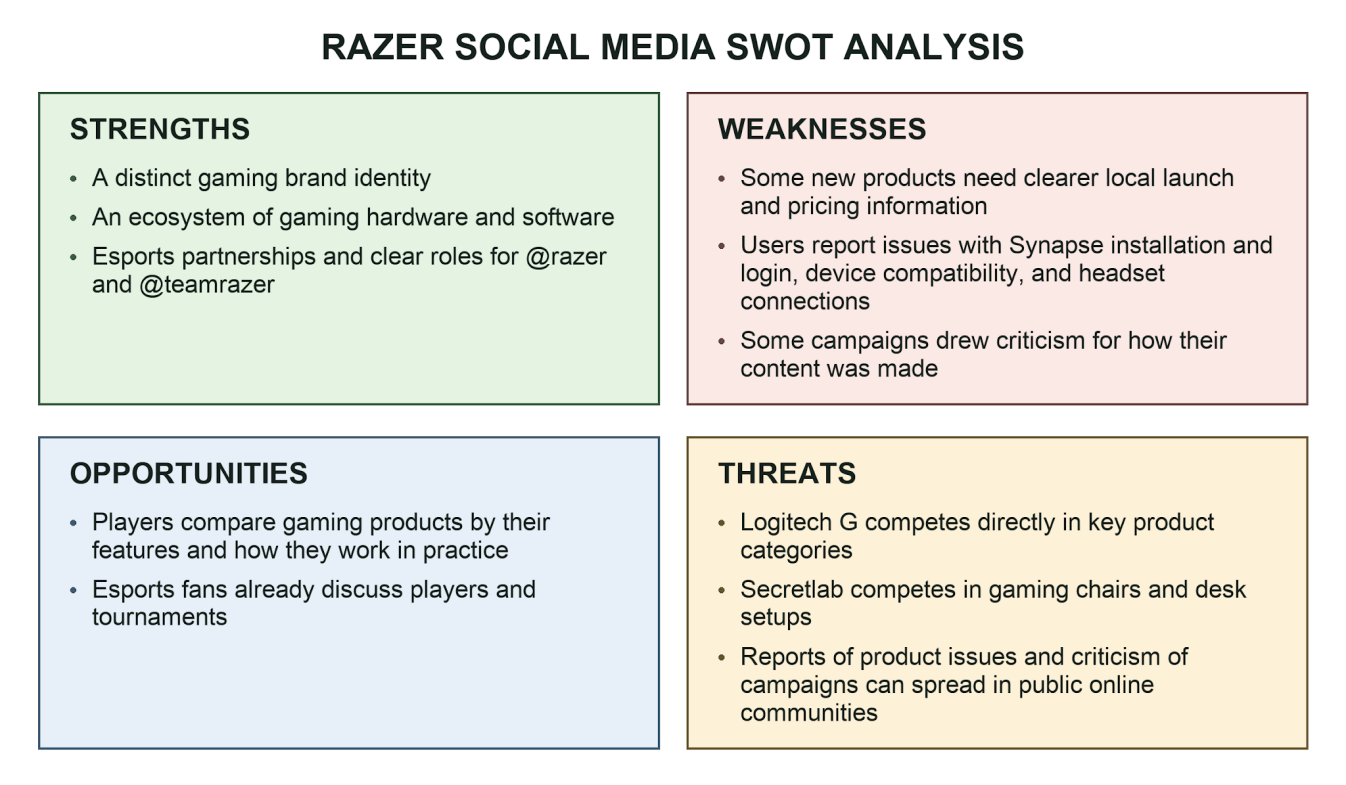

Figure 10. Razer social media SWOT

The SWOT analysis shows that the distinctive gaming brand positioning, software and hardware ecosystem and e-sports partnerships provide a basis for Razer to reach players and e-sports fans who pay attention to product performance. Players' attention to functional differences and discussions about players and competitions also provide opportunities for continuous communication for brands. The current weaknesses involve gaps in purchase information, the experience of using some products, and criticism of how some campaigns were made. These issues can come up in public comments and product comparisons, which may further affect consumers' evaluation of the brand. The competition of Logitech G in the core peripheral categories and Secretlab's competition in gaming chairs and desk setups highlight the importance of clearly explaining product differences and their value in practice.

<a id="report-121"></a>

### 6.2 Content Strategy Statement and Objectives

Razer should help the audience understand the product with specific demonstrations, respond to usage problems with practical guidelines, and provide opportunities for continuous participation through e-sports partnerships for players who are comparing gaming products, existing users who need help, and e-sports fans who follow players and events. @razer mainly undertakes product comparison, purchase information and usage guidance. @teamrazer mainly undertakes player stories, event discussions and fan submissions. Organic content is used for continuous explanation, answering questions and interaction, and paid content is used to disseminate suitable product demonstrations and event information to relevant audiences.

<a id="report-123"></a>

### 6.3 Suggestions for organic and paid content

<a id="report-124"></a>

#### 6.3.1 Use practical demonstrations to help players compare products

The Instagram analysis identified 262 comments on regional product availability and 91 on pricing. After new products were released, players also asked about specific functions and version differences. Discussions captured by Brand24 covered mouse lift-off distance, headset wireless connection and microphone performance, which shows that players want to know what the product differences mean in actual use.

@razer can provide supporting information when the new product is released, listing regional availability, prices and major version differences. Following Logitech G’s approach, Razer can ask players to explain a specific need and then demonstrate the relevant settings or functions. Drawing on Secretlab’s desk setup demonstration, Razer can also introduce multiple products in the same scene around a practical problem, such as showing how to adjust the chair, place the keyboard and mouse, and arrange the desk space when playing for a long time.

Razer can first publish these explanations and demonstrations organically to collect feedback. For paid promotion, it can select posts that performed well in saves, shares or product page clicks, show them to relevant players in markets where the product has launched, and link to the corresponding local product page. 

<a id="report-128"></a>

#### 6.3.2 Turn common usage problems into guidance and support

The negative-label rate is 57.87% for the synapse/software topic, 36.46% for the accounts/payments topic, and 34.19% for the headsets/audio topic. All three rates are higher than the overall rate of 18.10% in the final corpus. Specific posts involve issues such as Synapse installation and login, device compatibility, wireless connection and microphone use. These discussions identify issues to prioritize in user guides and customer support.

@razer can make short troubleshooting tutorials according to product model and software version, and pin frequently asked questions and links to official support portals under relevant posts. The social team is responsible for understanding the problems encountered by users, providing preliminary guidance, and referring cases that need individual attention to customer service or the technical team. The common problems found during follow-up can be used to update the tutorial. Account access and payment issues should be directed to the corresponding official services, and anti-fraud tips can be provided for third-party fraud.

Razer can use organic posts for routine tutorials and Q&A. When more users need to be notified about a confirmed problem, Razer can promote the official instructions in a targeted manner to help affected users find a solution promptly.

<a id="report-132"></a>

#### 6.3.3 Sustain fan participation around the same match

Of the 559 comments collected on Instagram posts exclusive to @teamrazer, 154 (27.55%) were classified into two topics related to e-sports and fan support. This shows that the account already has an audience interested in discussing players and competitions. Oracle Red Bull Racing released a race preview, a short post-race video and a recap with audience Q&A around the same Grand Prix, which provided a reference for @teamrazer to continue the discussion after a match.

@teamrazer can choose a match featuring a Razer partner player or team, introduce a game situation worth noting in the pre-match video, select a clip after the match, ask the player to explain their decision at that time, and then invite fans to submit examples of how they handled a similar situation. Some submissions can be selected for the follow-up content, and the players can comment on different approaches. Clips involving equipment choices and settings can be turned into product explainers for @razer.

Razer can first publish the series organically and track questions, submissions and follow-up discussions. Paid promotion can explain how to submit and when entries close to audiences interested in the relevant games or events. By responding to submissions, Razer can enrich the content of the event, and also give fans a reason to return to the brand account to see the feedback and continue to participate.

<a id="report-136"></a>

#### 6.3.4 Show how campaign content was made

Instagram comment analysis shows that the two topics of criticism of AI-related creative choices and unfollow/rejection involve a total of 253 comments, of which 133 were associated with a single post. This suggests that how the content was made was one factor some users considered when evaluating the campaign.

Razer can introduce the artists involved in co-branded campaigns and display concept sketches, production clips and design choices. Organic behind-the-scenes videos can show how the work was made, and paid co-branded advertising can clearly credit the creators and identify the source of the design. When choosing promotional materials, Razer can assess the audience's reaction to the product, design and production method based on feedback in the comments.

<a id="report-139"></a>

### 6.4 Four-week pilot and effect evaluation

Razer can use the four-week pilot to test product descriptions, troubleshooting Q&A and content that encourages e-sports fans to interact. Before the pilot, Razer can review the performance of similar posts in the previous four weeks and confirm the evaluation targets using historical account data. Instagram can serve as the main platform for posting and interaction. Complete product demonstrations and event recaps can be put on YouTube, and short clips focusing on a single action can be tested on TikTok. 

In the first week, @razer could publish product descriptions and tutorials addressing common questions. In the second week, it could use the comments to add function demonstrations and troubleshooting guides and give priority to responding to recurring problems. In the third week, Razer could select product demonstrations that performed well in saves and shares during the first two weeks of organic posting and carry out small-scale paid promotion in areas where the products have been launched. In the fourth week, Razer could continue to publish and answer questions, and compile data on post performance, customer service replies, event interaction and advertising. Product descriptions and routine Q&A would continue throughout the four weeks, and @teamrazer's pre-match previews, post-match recaps and feedback on fan submissions would follow the tournament schedule.

When evaluating product description posts, @razer can record the number of saves and shares each post receives per 100 people reached. Using the same observation period after publication for each post, Razer can compare the average performance of the pilot posts with that of similar organic posts in the previous four weeks, and the proposed target is a 10% increase over that baseline. At the same time, Razer can track how many product page clicks come from these posts.

For product issues, the proposed goal is for 90% of inquiries requiring a reply to receive an initial substantive response from a team member within 24 hours. Providing specific troubleshooting information, asking for details needed to solve the problem, or guiding users to contact the corresponding official support channels counts as a substantive response. Repeated inquiries about the same issue are counted together, and the outcomes of referred cases are recorded separately.

For e-sports content, Razer can track the number of eligible submissions, questions about match clips, and accounts that participate again on follow-up posts to observe whether the discussion continues. Paid promotion is evaluated according to its purpose. For product ads, Razer tracks product page clicks and cost per click. For ads inviting fan submissions, it tracks eligible submissions and cost per eligible submission.

After the end of the pilot, Razer can choose product demonstrations that are worth continuing according to their saves, shares and clicks, update the guidelines in response to recurring product issues, and decide whether to continue the event series according to fan submissions and follow-up discussions. Comments on the design and production methods of campaigns can also be used to adjust the next round of materials.

<a id="report-147"></a>

## References

Beijing Academy of Artificial Intelligence. (n.d.). BGE-base-en-v1.5 [Model card]. Hugging Face. Retrieved November 10, 2026, from https://huggingface.co/BAAI/bge-base-en-v1.5

ESL FACEIT Group. (2026, October 20). ESL FACEIT Group and Logitech G expand partnership to accelerate global alliance with IEM Beijing integration. https://eslfaceitgroup.com/press/esl-faceit-group-and-logitech-g-expand-partnership-to-accelerate-global-alliance-with-iem-beijing-integration/

Grootendorst, M. (2022). BERTopic: Neural topic modeling with a class-based TF-IDF procedure. arXiv. https://arxiv.org/abs/2203.05794

Logitech G. (n.d.). What is Designed with Pros? https://www.logitechg.com/en-us/discover/designed-with-pros/what-is-designed-with-pros

Logitech G. (2023, September 5). Inside look | PRO X Superlight 2 | Logitech G [Video]. YouTube. https://www.youtube.com/watch?v=P4Svc3ivXC8

Logitech International S.A. (2025). Annual report on Form 10-K for the fiscal year ended March 31, 2025. U.S. Securities and Exchange Commission. https://www.sec.gov/Archives/edgar/data/1032975/000103297525000029/logi-20250331.htm

Muniz, A. M., Jr., & O’Guinn, T. C. (2001). Brand community. Journal of Consumer Research, 27(4), 412–432. https://doi.org/10.1086/319618

Oracle Red Bull Racing [@redbullracing]. (2026a, November 8). From P21 to P2 🤯 Max Verstappen, everyone 🙌 #F1 #RedBullRacing #BrazilGP [Video]. Instagram. https://www.instagram.com/redbullracing/reel/Dffa3zHBLoc/

Oracle Red Bull Racing. (2026b, November 9). Reviewing Max Verstappen's P21 to P2 in Brazil GP! | Talking Bull! [Video]. YouTube. https://www.youtube.com/watch?v=lt-AlxePwT8

Oracle Red Bull Racing. (2026c, November 4). Why Brazil is an F1 fan favourite Grand Prix! | Oracle Virtual Laps [Video]. YouTube. https://www.youtube.com/watch?v=zD6aXTlx_UI

Razer. (n.d.-a). About Razer. https://www.razer.com/about-razer

Razer. (2025, February 20). Razer Viper V3 Pro | Faker Edition [Video]. YouTube. https://www.youtube.com/watch?v=LcDTqhAcEiE

Razer. (2026a, February 16). Introducing the Razer NiKo Collection: Co-designed with the Counter-Strike legend. https://www.razer.com/newsroom/product-news/razer-niko-collection

Razer. (2026b, April 19). Razer | Iskur V2 NewGen [Video]. YouTube. https://www.youtube.com/watch?v=AQuy__d6wOI

Razer [@razer]. (2026c, November 8). 16 years in the making. Congratulations to @mousesports on an incredible undefeated run at IEM Beijing 2026, claiming the title [Photographs]. Instagram. https://www.instagram.com/razer/p/DfgURJFl5WO/

Razer [@razer]. (2026d, November 9). Two Razer favorites come together for XBOX’s 25th anniversary. [Video]. Instagram. https://www.instagram.com/razer/reel/DfiI81gFIfY/

Secretlab. (n.d.). League of Legends esports x Secretlab chairs. https://secretlab.co/pages/lolesports

Secretlab. (2021, April 27). Secretlab MAGNUS Metal Desk demo guide [Video]. YouTube. https://www.youtube.com/watch?v=Cn8-07Kz3mk

Swani, K., & Labrecque, L. I. (2020). Like, comment, or share? Self-presentation vs. brand relationships as drivers of social media engagement choices. Marketing Letters, 31(2–3), 279–298. https://doi.org/10.1007/s11002-020-09518-8

Team Razer [@teamrazer]. (2026, October 27). The Unkillable Demon King returns to Singapore for the Razer | Faker Fan Event on 9 December 2026. More details [Photograph]. Instagram. https://www.instagram.com/teamrazer/p/DfBM9J4FzNm/

Word count: **5977** (including the main text, figure and table captions, and references; excluding the table of contents, abstract, and roles and contributions).

<a id="report-170"></a>

## Roles and Contributions

The report was divided by section leadership, with selected analytical parts jointly developed to integrate the group's evidence and interpretation.

- Wu Xia: Lead drafting of Part 1 (Social Media Audit and Strategic Objectives), Part 2 (Target Audience and Community Discourse), and Part 3 (What Works).

- Wang Xinyang: Lead responsibility for Methodology and data analysis; co-drafting of Part 3; joint contribution to Part 4 (Social Listening) and Part 5 (Competitive Benchmarking).

- Li Yunrui: Joint contribution to Part 4 (Social Listening) and Part 5 (Competitive Benchmarking); lead drafting of Part 6 (Data-Informed Content Strategy).

The Jupyter notebook containing the complete report and reproducible analysis code has been uploaded to GitHub: [https://github.com/Costawang/nmc5342-razer-social-listening/blob/main/notebooks/NMC5342_Razer_Final_Report.ipynb](https://github.com/Costawang/nmc5342-razer-social-listening/blob/main/notebooks/NMC5342_Razer_Final_Report.ipynb).